## Fractals

Four classic fractals, each a few lines of MATLAB, in one figure. The first two iterate `z = z.^2 + c` on a whole grid of complex numbers at once, with no loop over pixels: each step updates every point that has not escaped (`abs(z) > 2`) yet, and the picture shows the step at which each point escaped. The grids are coarse to keep this page small: raise them for a sharper picture.

In [ ]:
[re, im] = meshgrid(linspace(-2.2, 0.8, 36), linspace(-1.25, 1.25, 30));
c = re + 1i*im;  z = zeros(size(c));  mandel = zeros(size(c));
for k = 1:20
    in = abs(z) <= 2;  z(in) = z(in).^2 + c(in);  mandel(in) = k;
end
[jr, ji] = meshgrid(linspace(-1.6, 1.6, 36), linspace(-1, 1, 22));
w = jr + 1i*ji;  julia = zeros(size(w));
for k = 1:25
    in = abs(w) <= 2;  w(in) = w(in).^2 + (-0.8 + 0.156i);  julia(in) = k;
end
fprintf('%d of %d grid points stay in the Mandelbrot set\n', nnz(mandel == 20), numel(mandel))

242 of 1080 grid points stay in the Mandelbrot set


The Barnsley fern is an iterated function system: one of four affine maps, picked at random with fixed probabilities, moves a point at each step; 2000 points iterate together, a vector at a time, and the picture counts those landing in each cell of a grid (`accumarray`). The logistic map `x = r*x*(1 - x)` settles to one value for small `r`, then to 2, 4, 8, ... values, and turns chaotic near `r = 3.57`; its picture marks the cells each orbit visits.

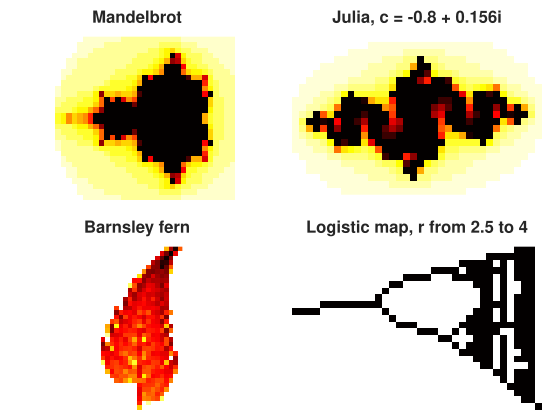

In [ ]:
figure
rng(1);
fx = zeros(2000, 1); fy = fx; P = zeros(0, 2);
for k = 1:25
    r = rand(2000, 1); gx = zeros(2000, 1); gy = gx;
    a = r < 0.01; b = r >= 0.01 & r < 0.86; c3 = r >= 0.86 & r < 0.93; d = r >= 0.93;
    gy(a) = 0.16*fy(a);
    gx(b) = 0.85*fx(b) + 0.04*fy(b);  gy(b) = -0.04*fx(b) + 0.85*fy(b) + 1.6;
    gx(c3) = 0.2*fx(c3) - 0.26*fy(c3); gy(c3) = 0.23*fx(c3) + 0.22*fy(c3) + 1.6;
    gx(d) = -0.15*fx(d) + 0.28*fy(d); gy(d) = 0.26*fx(d) + 0.24*fy(d) + 0.44;
    fx = gx; fy = gy;
    if k > 10, P = [P; fx, fy]; end
end
fern = accumarray([min(36, 1 + floor((10 - P(:, 2)) * 3.6)), min(20, 1 + floor((P(:, 1) + 2.75) / 5.5 * 20))], 1, [36 20]);
rs = linspace(2.5, 4, 36); xs = 0.5 * ones(size(rs)); orbit = zeros(24, 36);
for k = 1:300, xs = rs .* xs .* (1 - xs); end
for k = 1:100
    xs = rs .* xs .* (1 - xs);
    orbit(sub2ind([24 36], min(24, 1 + floor((1 - xs) * 24)), 1:36)) = 1;
end
subplot(2, 2, 1), imagesc(mandel), axis equal tight off, title('Mandelbrot')
subplot(2, 2, 2), imagesc(julia), axis equal tight off, title('Julia, c = -0.8 + 0.156i')
subplot(2, 2, 3), imagesc(log(1 + fern)), axis equal tight off, title('Barnsley fern')
subplot(2, 2, 4), imagesc(orbit), axis tight off, title('Logistic map, r from 2.5 to 4')
colormap(flipud(hot))

*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*